# Глава 5. Инструменты анализа пакетов (под капотом систем мониторинга)

5.1 Инструменты анализа пакетов

5.2 Wireshark: Анализ Сети

5.3 Роль разбора PCAP в системах мониторинга

5.4 Основные библиотеки Python для анализа PCAP

5.5 Анализ файлов захвата пакетов PCAP с помощью Scapy
(Python)
5.5.1 Сводка по Scapy

5.5.2 Пример: Генерация и анализ ICMP-пакета (Ping)

5.5.3 Пример: Генерация "Угрозы" (SYN Scan)

5.5.4 Пример: Генерации PCAP-файла с разным трафиком
(протоколы)

5.5.5 Пример с реальным PCAP-файлом


# 5.1 Инструменты анализа пакетов

Инструменты анализа пакетов (packet analysis tools) используются для **захвата, просмотра и анализа сетевого трафика**.  
Они помогают в диагностике сетевых проблем, обеспечении безопасности, тестировании производительности и обнаружении вторжений.

---

## 1. Графические анализаторы (GUI-ориентированные)

**Wireshark** — самый популярный инструмент для анализа пакетов.  
Позволяет фильтровать и декодировать сетевой трафик, визуализировать обмен данными и анализировать сотни протоколов.  
*(кроссплатформенный, open-source)*

**Microsoft Message Analyzer (снят с поддержки)** — ранее использовался для анализа сетевого трафика и событий Windows; для новых проектов его применять не рекомендуется.

**EtherApe** — визуализирует сетевую активность в виде графа, где узлы и связи меняются по нагрузке.

---

## 2. Консольные инструменты

**tcpdump** — классический инструмент командной строки для захвата и фильтрации пакетов.  
Пример:
```bash
tcpdump -i eth0 port 80 -w capture.pcap
```

**tshark** — консольная версия Wireshark; поддерживает те же фильтры и форматы.

**ngrep** — позволяет искать текстовые шаблоны в сетевом трафике (аналог grep, но для пакетов).

**dumpcap** — лёгкий инструмент для захвата пакетов, используемый внутри Wireshark.
## 3. Инструменты для сетевой безопасности и IDS/IPS

Используются для обнаружения атак и анализа инцидентов.

**Snort** — система обнаружения вторжений (IDS/IPS), может анализировать пакеты в реальном времени.

**Suricata** — продвинутая альтернатива Snort с поддержкой многопоточности.

**Bro/Zeek** — мощный фреймворк для сетевого мониторинга и анализа поведения.

## 4. Специализированные и вспомогательные утилиты

NetFlow / sFlow analyzers — анализ потоков, а не отдельных пакетов (например, SolarWinds, ntopng).

NetworkMiner — инструмент для извлечения файлов, изображений, паролей из pcap-захватов.

**Colasoft Capsa** — коммерческий анализатор с визуализацией и отчётами.

**Xplico** — инструмент для реконструкции приложений (HTTP, VoIP, Email и т. д.) из pcap.

# 5.2 Wireshark: Анализ Сети

### 1. Определение программы
**Wireshark** — это ведущий в мире **Анализатор Сетевых Протоколов** (или "сниффер").

Его основная задача — захватывать доступные сетевому интерфейсу пакеты и декодировать поддерживаемые протоколы. Видимость трафика зависит от типа сети, режима захвата, настроек интерфейса и шифрования; содержимое зашифрованных соединений обычно нельзя прочитать без дополнительных условий.

### 2. Основные функции и принцип работы

| Функционал | Что это значит | Аналогия |
| :--- | :--- | :--- |
| **Захват (Capture)** | Перевод адаптера в **неразборчивый режим (promiscuous mode)** (promiscuous mode) для сбора всего трафика, доступного в сегменте сети. | **Запись** всех телефонных разговоров на линии. |
| **Декодирование (Decode)** | Разбиение "сырого" пакета на логические слои (**Ethernet**, **IP**, **TCP/UDP**) и отображение их полей (порты, флаги, данные) в читаемом виде. | **Переводчик**, который разбирает письмо по параграфам, предложениям и словам. |
| **Фильтрация (Filter)** | Применение мощных правил (например, `ip.addr == 1.1.1.1` или `tcp.port == 80`) для поиска конкретных пакетов в огромном потоке данных. | **Поисковая система**, которая мгновенно находит нужную иглу в стоге сена. |

### 3. Рабочий процесс (четыре шага)

1.  **Установка:** Скачайте и установите программу с официального сайта **wireshark.org** (обязательно установите **Npcap** на Windows).
2.  **Начало Захвата:** Выберите сетевой интерфейс (Wi-Fi, Ethernet) и нажмите кнопку **"Start capturing packets"**.
3.  **Генерация Трафика:** Выполните действие, которое хотите проанализировать (откройте сайт, отправьте Ping).
4.  **Анализ:** Остановите захват и используйте **панель фильтров** (например, `dns` или `http`) для изоляции нужного трафика.

### 4. Ключевые Панели Интерфейса
* **Панель 1 (Сверху): Список Пакетов:** Сводка: Время, Источник, Получатель, Протокол, Краткая информация.
* **Панель 2 (Середина): Детали Пакета:** Иерархическое дерево слоев (**Packet Details**). Здесь вы видите все поля: MAC-адреса, TTL, порты, флаги.
* **Панель 3 (Снизу): Байт-Дамп:** Сырые данные пакета в шестнадцатеричном и ASCII-формате.

В сети Интернет есть много материалов по приложению см.

[Wireshark — подробное руководство по началу использования](https://habr.com/ru/articles/735866/)

[Дополнительное видео: Analyzing capture files in Python with PyShark](https://youtu.be/qxBKHsMhWKU?si=Ta3VFq4a9qLX5t11)

### 5.3 Роль разбора PCAP в системах мониторинга


**Разбор PCAP (Packet Capture)** — это процесс чтения и анализа пакетов, сохранённых в файле захвата. Такой файл может содержать трафик, захваченный с сетевого интерфейса или сформированный другим способом. В системах мониторинга (Network Monitoring) и безопасности (Security Operations) он является критически важным инструментом для **глубокой диагностики**, **форензики** и **детекции сложных угроз**.

## Ключевые роли разбора PCAP

| Роль | Описание |
| :--- | :--- |
| **Глубокая диагностика инцидентов (RCA)** | Восстановление полной последовательности сетевых событий, просмотр заголовков, полезной нагрузки и точных таймингов для выявления **первопричины** проблем. |
| **Форензика и расследования** | Реконструкция TCP-стримов, извлечение файлов/сессий, поиск индикаторов компрометации (IoC), C2-активности, сканирования и утечек данных (**форензика** — исследование цифровых следов и сбор доказательств инцидента). |
| **Верификация и отладка приложений** | Точная проверка того, что приложение фактически передает по сети (DNS, HTTP-заголовки, ошибки TLS/SSL). |
| **Проверка производительности и латентности** | Измерение RTT (Round Trip Time), выявление потерь пакетов, повторных передач и задержек на уровне L2-L4. |
| **Обогащение SIEM/IDS/IPS** | Извлечение базовых метрик (частота, размер, интервалы) для более богатого контекста и точечного **аномалия-детекта**. |
| **Реконструкция потоков** | Восстановление целых объектов, таких как переданные файлы, HTTP-ответы или VoIP-сессии. |

---

## Стратегии захвата и сбора PCAP

Постоянное хранение полных PCAP экономически невыгодно. Поэтому используются следующие стратегии:

1.  **Критические участки сети:** Приоритетный захват на границах **периметра**, в **DMZ**, на **API-шлюзах** и перед **базами данных**.
2.  **Триггерные снимки:** Захват включается только при срабатывании алерта (например, от IDS/IPS или SIEM) или при обнаружении аномалии.
3.  **Сэмплинг (Выборочный захват):** Сбор только части трафика (например, каждый $N$-й пакет) или только заголовков.

---

## Преимущества и ограничения

| Преимущества | Ограничения |
| :--- | :--- |
| **Непревзойдённая детализация** (заголовки + полезная нагрузка). | **Объём и производительность:** PCAP требует дорогостоящего хранения и высокой пропускной способности I/O. |
| **Доказательная база** для расследований и реконструкции сессий. | **Шифрование (TLS/HTTPS):** Скрывает полезную нагрузку. Без ключей расшифрования обычно доступны метаданные (например, адреса, размеры и тайминги; видимость SNI и сертификатов зависит от версии TLS и конфигурации). |
| **Широкая применимость:** позволяет анализировать множество сетевых протоколов; глубина разбора зависит от используемых инструментов и доступных данных. | **Конфиденциальность:** PCAP может содержать **персональные данные** (PII) и пароли, что требует строгих политик доступа, шифрования и соответствия (GDPR, HIPAA). |
| | **Сложность обработки в реальном времени** для сред с высокой пропускной способностью (high-throughput). |

---

## Архитектура пайплайна разбора PCAP

Для эффективной работы PCAP-анализ интегрируется в общую систему мониторинга:

1.  **Захват (Ingest):** Используются **TAP-порты** или **SPAN/Mirror-порты**. Обязательно применение **BPF-фильтров** (Berkeley Packet Filter) для минимизации объёма захвата (например, `tcp port 80 or icmp`).
2.  **Буферизация и очередь:** Захваченные блоки PCAP отправляются в асинхронную шину данных, такую как **Kafka** или **S3/Blob Storage**, для отложенной и масштабируемой обработки.
3.  **Предобработка и Парсинг:** Инструменты (Zeek, Suricata, TShark) извлекают метаданные (IP, порты, таймштампы, TCP-флаги, длина), сегментируют трафик на сессии и дедуплицируют пакеты.
4.  **Индексирование и Хранение:**
    * **Метаданные/Эвенты:** Хранятся в быстром индексе (Elasticsearch, ClickHouse) для быстрого поиска и корреляции.
    * **PCAP-файлы:** Хранятся в **холодном (объектном) хранилище** (S3/GCS/MinIO) со ссылками в основном индексе.
5.  **Интеграция в SIEM:** Эвенты из PCAP-анализа (например, алерты Zeek) используются для корреляции с логами хостов, аутентификацией и другими источниками данных.

---

## Инструментарий (кратко)

| Фаза | Инструменты |
| :--- | :--- |
| **Захват** | `tcpdump`, `dumpcap`, AF_PACKET |
| **Реал-тайм анализ/Эвенты** | **Zeek** (ранее Bro), **Suricata**, Snort |
| **Офлайн разбор/Форензика** | **Wireshark**, PyShark, Scapy, NetworkMiner |
| **Хранение** | S3/GCS, ClickHouse, Elasticsearch |

---

## Лучшие практики

* **Раздельное хранение:** рекомендуется сохранять **метаданные (индексы, хэши, тайминги)** отдельно от сырых PCAP-файлов. Это удешевляет поиск и хранение.
* **Гибридное хранение:** рекомендуется использовать **"горячее"** (последние 7–30 дней) и **"холодное"** (долговременный архив) хранение для PCAP.
* **Анонимизация:** рекомендуется внедрить политику анонимизации чувствительных полей (например, IP-адресов) при хранении или предоставлении PCAP аналитикам.
* **Мониторинг процесса:** Следите за метриками **`dropped packets`**, нагрузкой на CPU и I/O, чтобы гарантировать, что вы не теряете данные.

---



## 5.4 Основные библиотеки Python для анализа PCAP

Для анализа файлов захвата пакетов PCAP (packet capture) в Python используются следующие популярные библиотеки:

Основные библиотеки для анализа PCAP

1. **Scapy**: Это мощный инструмент и библиотека для манипулирования и анализа пакетов. Он позволяет читать, писать, отправлять, снифить и подделывать сетевые пакеты. Scapy очень популярен для пентестинга, сетевого анализа и разработки инструментов безопасности. Для чтения PCAP-файлов используется функция rdpcap() или генератор PcapReader().
**Тип:** интерактивная и универсальная библиотека для работы с пакетами

**Функционал:**
- Захват, генерация и анализ пакетов  
- Поддержка множества протоколов (IP, TCP, ARP, ICMP, DNS и др.)  
- Удобна для тестирования, pentest-скриптов и обучения  
**Ограничения:** загрузка всего файла через `rdpcap()` может требовать много памяти; для потокового чтения подходит `PcapReader()`  


2. **PyShark**: Оболочка (wrapper) для TShark (версия Wireshark для командной строки). Он позволяет анализировать пакеты, используя возможности декодирования протоколов Wireshark, что делает его очень мощным для детального, многоуровневого анализа.
**Тип**: Python-обёртка над Wireshark/TShark.
**Сильные стороны:**
Использует движок Wireshark → высокая точность разбора
Простые фильтры (display_filter, capture_filter)
Отлично подходит для анализа протоколов
**Ограничения:** требует установленный TShark; накладные расходы могут снижать скорость обработки

3. **DPKT**: Легкий и быстрый пакетный анализатор для Python. Он поддерживает множество протоколов и часто используется для быстрого парсинга PCAP-файлов.
**Тип**: низкоуровневая, быстрая библиотека для парсинга пакетов
**Сильные стороны**:
Очень высокая производительность
Подходит для потоковой обработки больших pcap
Простая структура данных
**Ограничения:** набор поддерживаемых протоколов и глубина разбора отличаются от Wireshark/Scapy; сложные сценарии могут потребовать дополнительного кода

4. **PyPCAPKit** (PyPCAPKit): Комплексная библиотека для парсинга и анализа сетевых пакетов, позиционируется как более всеобъемлющая альтернатива Scapy, DPKT и PyShark, предлагая более подробную информацию о пакетах.
**Тип**: модульная библиотека для глубокого анализа и реконструкции пакетов
**Сильные стороны:**
Глубокий протокольный анализ (до уровня приложений)
Гибкая архитектура (parsers, engines, pipelines)
Поддержка PCAP/PCAPNG, TCP stream reassembly
**Минусы:** сложнее в освоении, менее распространена



# Сравнение библиотек для анализа pcap-файлов в Python

| Библиотека   | Тип                                   | Скорость     | Точность         | Простота       | Основное применение |
|---------------|---------------------------------------|---------------|------------------|----------------|----------------------|
| **Scapy**     | Интерактивная, универсальная          | 🟡 Средняя    | 🟢 Высокая        | 🟢 Простая      | Создание и анализ пакетов (pentest, обучение) |
| **PyShark**   | Обёртка над Wireshark/TShark          | 🔴 Низкая     | 🟢 Очень высокая  | 🟡 Средняя      | Глубокий анализ протоколов (HTTP, DNS, TLS) |
| **DPKT**      | Низкоуровневая, быстрая               | 🟢 Высокая    | 🟡 Средняя        | 🟡 Средняя      | Быстрая обработка больших pcap-файлов |
| **PyPCAPKit** | Модульная, для глубокого анализа      | 🟡 Средняя    | 🟢 Очень высокая  | 🔴 Сложная      | Реконструкция потоков, исследовательские задачи |

---

### Краткие выводы по применению:
- **Scapy** — лучше всего подходит для обучения, экспериментов и пентестов.  
- **PyShark** — оптимален для точного разбора и фильтрации трафика.  
- **DPKT** — идеален для быстрого офлайн-анализа больших объёмов.  
- **PyPCAPKit** — мощный инструмент для детальной реконструкции сетевых потоков.


## 5.5 Анализ файлов захвата пакетов PCAP с помощью Scapy

Библиотека Scapy — удобный инструмент для создания, чтения и анализа сетевых пакетов. Для обучения особенно полезны следующие возможности:

1. Интерактивность и простота использования: Scapy разработан для интерактивной работы, что позволяет быстро экспериментировать и видеть результаты. Вы можете легко читать пакеты, получать доступ к их полям и манипулировать ими.

1. Двунаправленная функциональность: В отличие от библиотек, которые являются только парсерами (например, dpkt), Scapy также позволяет создавать и отправлять пакеты. Это дает более полное понимание работы сети и позволяет проводить практические эксперименты (например, построить простой сканер или спуфер).

1. Мощный анализ протоколов: Scapy поддерживает огромное количество сетевых протоколов и позволяет легко разбирать пакеты по слоям (Ethernet, IP, TCP/UDP и т. д.). Например, для чтения пакетов из файла используется простая команда rdpcap('file.pcap').

1. Популярность в сфере безопасности: Scapy — это стандартный инструмент в области сетевой безопасности и пентестинга, поэтому освоение этой библиотеки имеет прямую практическую ценность.

Чтение PCAP: packets = rdpcap('file.pcap')

Доступ к полям: packets[0][IP].src (получить исходный IP первого пакета) т.е. полю (.src, то есть "Source IP Address" — Исходный IP-адрес) внутри первого пакета (packets[0]) из захваченного файла, который был разобран на уровне IP ([IP]).

Фильтрация: [p for p in packets if p.haslayer(TCP)] (отфильтровать только TCP-пакеты)

Визуализация/Печать: packets[0].show() (показать полное дерево протоколов пакета)


## 5.5.1 Сводка по Scapy

Scapy — это мощная интерактивная программа и библиотека на Python, предназначенная для манипуляций сетевыми пакетами. Она используется сетевыми инженерами, специалистами по безопасности и исследователями для создания, отправки, захвата и анализа сетевого трафика.

1. Что такое Scapy и его возможности

    Создание (Forging) Пакетов: Scapy позволяет создавать сетевые пакеты "с нуля", наслаивая протоколы друг на друга (например, Ether/IP/TCP). Пользователь имеет полный контроль над каждым полем пакета, что критически важно для тестирования и безопасности.

    Чтение и Захват (Sniffing): Библиотека может захватывать живой трафик с сетевого интерфейса (подобно tcpdump) или читать сохраненные файлы захвата пакетов (PCAP).

    Отправка и Прием: Scapy позволяет отправлять как пакеты Уровня 3 (IP), так и пакеты Уровня 2 (Ethernet), а также сопоставлять отправленные запросы с полученными ответами.

    Декодирование и Разбор (Dissection): Scapy автоматически разбирает пакеты по слоям протоколов (Ethernet, IP, TCP, UDP, ICMP, DNS и множество других), предоставляя доступ к их внутренним полям.

    Замена других инструментов: Scapy часто используется для замены или дополнения функционала таких инструментов, как Nmap (для сканирования), tcpdump (для сниффинга) и hping (для создания пакетов).

|Действие	|Команда Scapy (в Python)	|Описание                      |
|---------------|-------------------------------|------------------------------|
|Создание	|pkt = IP()/TCP()	|Создает пакет, состоящий из IP и TCP.
|Просмотр	|pkt.show()	|Выводит детальный разбор пакета по полям.
|Сводка	pkt.summary()	|Выводит краткое описание пакета.
|Чтение PCAP	|packets = rdpcap("file.pcap")	|Читает пакеты из файла.
|Захват	sniff(count=10)	|Захватывает 10 пакетов с интерфейса.
|Отправка	|send(pkt)	|Отправляет пакет на уровне 3 (IP).

Внимание: Для отправки и сниффинга пакетов (команды send() и sniff()) на большинстве систем требуются права администратора (например, запуск скрипта через sudo).

 ## Создание и анализ пакетов (Packet Crafting & Show)


|Задача	|Команда Scapy	|Описание и Результат|
|-------|---------------|--------------------|
|Создание TCP SYN	|syn_pkt = IP(dst="192.168.1.1")/TCP(dport=80, flags="S")	|Создает пакет с заголовками IP и TCP. IP-адрес назначения установлен, TCP-порт назначения установлен на 80, и флаг SYN ("S") активирован.|
|Создание DNS-запроса	|dns_query = IP(dst="8.8.8.8")/UDP(dport=53)/DNS(qd=DNSQR(qname="google.com"))	|Создает запрос DNS для домена google.com (направленный на публичный DNS Google).|
|Просмотр структуры	|syn_pkt.show()	|Выводит детальную, многослойную структуру пакета, включая все поля и их значения по умолчанию.|
|Краткий обзор	|print(syn_pkt.summary())	|Выводит краткое, однострочное описание: IP / TCP.|
|Доступ к полю	|print(syn_pkt[IP].dst)	|Выводит значение поля назначения IP-уровня: "192.168.1.1".|

## Чтение и запись файлов PCAP (Read & Write)

|Задача	|Команда Scapy	|Описание и Результат|
|-------|---------------|---------------------|
|Чтение PCAP-файла	|packets = rdpcap("test.pcap")	|Загружает все пакеты из файла test.pcap в объект типа PacketList.|
|Просмотр первого пакета	|packets[0].show()	|Отображает детальную структуру первого пакета из списка.|
|Получение количества	|print(len(packets))	|Выводит общее количество пакетов в файле.|
|Запись в PCAP	|wrpcap("output.pcap", syn_pkt)	|Записывает созданный пакет (syn_pkt) в новый файл output.pcap.|

## Отправка и прием пакетов (Send & Sniff)

|Задача	|Команда Scapy	|Описание и Результат|
|-------|---------------|---------------------|
|Отправка на Уровне 3	|send(IP(dst="127.0.0.1")/ICMP())	|Отправляет один ICMP-пакет (Ping) на адрес локальной петли. Отправка без учета MAC-адресов.|
|Отправка и ожидание ответа	|ans, unans = sr1(IP(dst="8.8.8.8")/ICMP(), timeout=1)	|Отправляет пакет и ждет один ответ (sr1 = send/receive 1). |Возвращает ответ (ans) и неотвеченный запрос (unans).|
|Захват трафика	|sniff(iface="eth0", filter="tcp port 22", count=5)	|Захватывает 5 пакетов, проходящих через интерфейс eth0, которые соответствуют фильтру BFP (только TCP-трафик на порту 22).|
|Автоматический анализ при сниффинге	|sniff(prn=lambda x: x.summary(), count=10)	|Захватывает 10 пакетов и для каждого вызывает анонимную функцию (lambda), которая печатает его краткую сводку.|


## 5.5.2 Пример: генерация и анализ ICMP-пакета (Ping)

Мы сгенерируем простой пакет ICMP (запрос Ping), а затем используем встроенные методы Scapy для его анализа.

## 1. Генерация пакета

In [7]:
 # установка библиотеки
!pip install scapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 13.6 MB/s  0:00:00 eta 0:00:01


In [8]:
from scapy.all import IP, ICMP, Raw

# 1. Создаем пакет: наслаиваем протоколы друг на друга
# Пакет состоит из:
# - IP-уровня с указанием IP-адреса назначения (dst)
# - ICMP-уровня (это будет запрос echo, т.е. Ping)
# - Необработанных данных (Raw), служащих полезной нагрузкой
generated_packet = IP(dst="8.8.8.8")/ICMP() / Raw(load="Hello Scapy")

# Примечание: Pcap-файл (PCAP) обычно содержит пакеты, захваченные с помощью сниффера.
# Этот код показывает, как анализировать пакет, созданный "с нуля" в памяти,
# что является ключевой функцией Scapy.
print('generated_packet \n',generated_packet)

generated_packet 
 IP / ICMP 192.168.10.153 > 8.8.8.8 echo-request 0 / Raw


## 2. Анализ и визуализация

Для анализа и визуализации сгенерированного пакета в Scapy есть несколько удобных методов:

A. Детальный текстовый вывод (.show())

Этот метод является наиболее распространенным и показывает структуру пакета по слоям, а также значения всех полей.

In [9]:
# Детальный анализ структуры и полей
generated_packet.show()

###[ IP ]###
  version   = 4
  ihl       = None
  tos       = 0x0
  len       = None
  id        = 1
  flags     = 
  frag      = 0
  ttl       = 64
  proto     = icmp
  chksum    = None
  src       = 192.168.10.153
  dst       = 8.8.8.8
  \options   \
###[ ICMP ]###
     type      = echo-request
     code      = 0
     chksum    = None
     id        = 0x0
     seq       = 0x0
     unused    = b''
###[ Raw ]###
        load      = b'Hello Scapy'



B. Визуализация в виде диаграммы PostScript/PDF (.psdump() / .pdfdump())

Scapy имеет встроенную функцию, которая генерирует графическое представление пакета, показывая его структуру слоями. Для работы этой функции обычно требуется установка внешних инструментов, таких как Graphviz и LaTeX/PostScript (например, MiKTeX или TeX Live).

C. Краткое суммарное представление (.summary())

Используется для быстрого обзора содержимого пакета.

In [10]:
# Краткий обзор
print(generated_packet.summary())

IP / ICMP 192.168.10.153 > 8.8.8.8 echo-request 0 / Raw


### Дополнительный материал:
[Intro to the Scapy Packet Manipulation Tool](https://www.youtube.com/watch?v=XsMoZIlznOI)

Это видео демонстрирует основные возможности Scapy по манипуляции сетевыми пакетами, что является необходимым шагом для их последующего анализа и визуализации.

## 5.5.3 Пример: моделирование SYN-сканирования

SYN-сканирование — метод проверки доступности TCP-портов, при котором отправляются SYN-пакеты без завершения полного TCP-рукопожатия. В этом примере пакеты только записываются в файл; они не отправляются в сеть.

Сформируем синтетический набор из 10 SYN-пакетов с одним исходным IP-адресом на разные порты условного целевого узла. Это имитация для офлайн-анализа, а не реальное сканирование.

### 1. Генерация пакета с угрозой

In [2]:
from scapy.all import IP, TCP, wrpcap, RandIP, RandShort

# 1. Параметры сканирования
target_ip = "192.168.1.100" # Цель сканирования
source_ip = str(RandIP())   # Случайный исходный IP-адрес для маскировки
num_ports = 10              # Количество сканируемых портов

# 2. Генерация пакетов
syn_packets = []
for port in range(5000, 5000 + num_ports):
    # Создаем TCP SYN пакет, где S = SYN-флаг
    packet = IP(src=source_ip, dst=target_ip) / TCP(dport=port, flags="S", sport=RandShort())
    syn_packets.append(packet)

# 3. Сохранение сгенерированного трафика в PCAP-файл
file_name = "syn_scan_traffic.pcap"
wrpcap(file_name, syn_packets)
print(f"[+] Сгенерировано {len(syn_packets)} SYN-пакетов и сохранено в {file_name}.")

[+] Сгенерировано 10 SYN-пакетов и сохранено в syn_scan_traffic.pcap.


### 2. Обнаружение Угрозы   

Теперь мы читаем файл и ищем закономерность, характерную для SYN-сканирования: большое количество пакетов с флагом SYN, исходящих от одного источника.

In [1]:
from scapy.all import rdpcap, TCP, IP
from collections import Counter

# 1. Чтение сгенерированного файла
packets = rdpcap("syn_scan_traffic.pcap")

# 2. Фильтрация и извлечение данных
syn_requests = []
scan_source_ip = None

for packet in packets:
    # Проверяем, что это TCP-пакет и установлен только флаг SYN (0x02)
    if packet.haslayer(TCP) and packet[TCP].flags == 0x02:
        syn_requests.append(packet[IP].src)

# 3. Анализ частоты
# Считаем, сколько SYN-запросов отправил каждый IP-адрес
scan_counts = Counter(syn_requests)

# 4. Обнаружение
print("\n--- Результаты анализа трафика ---")
if not syn_requests:
    print("[-] TCP SYN-трафик не обнаружен.")
else:
    # Определяем, какой IP-адрес отправил наибольшее количество SYN-запросов
    potential_scanner, count = scan_counts.most_common(1)[0]

    # Пороговое значение для обнаружения (например, более 5 SYN-пакетов за короткое время)
    threshold = 5

    print(f"[!] Обнаружены SYN-запросы от {len(scan_counts)} уникальных IP-адресов.")

    if count >= threshold:
        print(f"!!! УГРОЗА ОБНАРУЖЕНА !!!")
        print(f"Подозрительный IP-адрес сканера: {potential_scanner}")
        print(f"Количество обнаруженных SYN-запросов: {count}")
        print("Это соответствует паттерну **SYN-сканирования портов**.")
    else:
        print("[-] Количество SYN-запросов не превышает порог обнаружения.")

# 5. Вывод для наглядности
print("\n--- Пример анализа одного подозрительного пакета ---")
if syn_requests:
    # Находим первый пакет от сканера для детального просмотра
    for pkt in packets:
        if pkt.haslayer(IP) and pkt[IP].src == potential_scanner:
            pkt.show()
            break


--- Результаты анализа трафика ---
[!] Обнаружены SYN-запросы от 1 уникальных IP-адресов.
!!! УГРОЗА ОБНАРУЖЕНА !!!
Подозрительный IP-адрес сканера: 42.128.207.46
Количество обнаруженных SYN-запросов: 10
Это соответствует паттерну **SYN-сканирования портов**.

--- Пример анализа одного подозрительного пакета ---
###[ IP ]###
  version   = 4
  ihl       = 5
  tos       = 0x0
  len       = 40
  id        = 1
  flags     = 
  frag      = 0
  ttl       = 64
  proto     = tcp
  chksum    = 0xbf14
  src       = 42.128.207.46
  dst       = 192.168.1.100
  \options   \
###[ TCP ]###
     sport     = 49713
     dport     = 5000
     seq       = 0
     ack       = 0
     dataofs   = 5
     reserved  = 0
     flags     = S
     window    = 8192
     chksum    = 0xfe6d
     urgptr    = 0
     options   = []



### 3. Принцип обнаружения

Обнаружение угроз в данном случае основано на простом эвристическом правиле:

    Сбор статистики: Мы подсчитываем количество TCP-пакетов, у которых установлен только флаг SYN (0x02), для каждого исходного IP-адреса.

    Сравнение с порогом: Если один IP-адрес отправляет подозрительно большое количество таких пакетов (count >= 5) на разные порты целевого хоста без получения или отправки других флагов (ACK/FIN), это является признаком, требующим дополнительной проверки, и может соответствовать сканированию портов. По одному этому признаку нельзя достоверно установить факт атаки: легитимные приложения также могут отправлять много SYN-пакетов.

Публичные репозитории сетевого трафика

Это наиболее рекомендуемые источники, поскольку они предлагают разнообразные и часто аннотированные (с описанием того, что в них содержится) записи трафика.

    Wireshark Sample Captures (Сэмплы Wireshark) :

        Особенность: Официальная страница проекта Wireshark, где собраны тестовые файлы .pcap и .pcapng для демонстрации и тестирования различных протоколов (от обычного HTTP до экзотических). Это отличный источник для учебных целей.

    Malware-Traffic-Analysis.net (Анализ вредоносного трафика) :

        Особенность: Один из лучших источников для реального трафика вредоносного ПО. Файлы часто предоставляются вместе с заданиями для анализа, что идеально подходит для обучения сетевой безопасности.

    PCAP Library (Библиотека PCAP):

        Особенность: Различные репозитории, созданные сообществом, содержащие как обычный, так и аномальный трафик (например, записи сетевых атак, сканирования).

## 5.5.4 Пример: создание PCAP-файла с пакетами разных типов

### 1. Генерация файла с разным трафиком

In [3]:
from scapy.all import IP, ICMP, TCP, wrpcap

# 1. Генерация ICMP-трафика (Ping)
# 3 пакета ICMP-эхо-запроса
icmp_packets = [
    IP(dst="8.8.8.8", id=i) / ICMP()
    for i in range(1, 4)
]

# 2. Генерация HTTPS-трафика (TCP на порту 443)
# 3 пакета SYN-запросов к веб-серверу (имитация начала HTTPS-соединения)
https_packets = [
    IP(dst="203.0.113.10", id=i) / TCP(dport=443, flags="S")
    for i in range(4, 7)
]

# 3. Генерация FTP-трафика (TCP на порту 21)
# 3 пакета ACK (подтверждение) на FTP-порт (имитация активного FTP-соединения)
ftp_packets = [
    IP(dst="198.51.100.5", id=i) / TCP(dport=21, flags="A")
    for i in range(7, 10)
]

# 4. Объединение и запись всех пакетов в один файл
all_packets = icmp_packets + https_packets + ftp_packets
file_name = "multi_protocol_traffic.pcap"
wrpcap(file_name, all_packets)

print(f"[+] PCAP-файл '{file_name}' создан с {len(all_packets)} пакетами.")

[+] PCAP-файл 'multi_protocol_traffic.pcap' создан с 9 пакетами.


### 2. Анализ PCAP-файла и подсчёт пакетов по категориям
Этот код читает созданный PCAP-файл и использует возможности Scapy для разбора пакетов и подсчета их по протоколам.

In [4]:
from scapy.all import rdpcap, IP, TCP, ICMP

# 1. Чтение сгенерированного PCAP-файла
file_name = "multi_protocol_traffic.pcap"
packets = rdpcap(file_name)

# 2. Инициализация счетчиков
protocol_counts = {
    "ICMP": 0,
    "HTTPS (TCP 443)": 0,
    "FTP (TCP 21)": 0,
    "Другой TCP": 0,
    "Неизвестный": 0
}

# 3. Анализ каждого пакета
for pkt in packets:
    # Проверяем наличие IP-уровня (для сетевых протоколов)
    if pkt.haslayer(IP):
        # Проверка ICMP (Протокол 1 на IP-уровне)
        if pkt.haslayer(ICMP):
            protocol_counts["ICMP"] += 1

        # Проверка TCP (Протокол 6 на IP-уровне)
        elif pkt.haslayer(TCP):
            dport = pkt[TCP].dport  # Порт назначения

            if dport == 443:
                protocol_counts["HTTPS (TCP 443)"] += 1
            elif dport == 21:
                protocol_counts["FTP (TCP 21)"] += 1
            else:
                protocol_counts["Другой TCP"] += 1

        # ... можно добавить другие протоколы (UDP, ARP и т.д.)

        else:
            # Сюда попадут, например, пакеты с протоколами GRE, EIGRP и т.д.
            protocol_counts["Неизвестный"] += 1

    else:
        # Сюда попадут пакеты без IP-уровня (например, только Ethernet или ARP)
        protocol_counts["Неизвестный"] += 1

# 4. Вывод результатов анализа
print(f"\n--- Разбор трафика из '{file_name}' ---")
print(f"Всего пакетов проанализировано: {len(packets)}")
for proto, count in protocol_counts.items():
    if count > 0:
        print(f"  > {proto}: {count} пакетов")

# 5. Вывод детального разбора для примера (первый ICMP-пакет)
print("\n--- Детальный разбор первого ICMP-пакета (пример) ---")
# Фильтруем и выводим первый пакет с ICMP
icmp_packet = packets.filter(lambda p: p.haslayer(ICMP))[0]
icmp_packet.show()


--- Разбор трафика из 'multi_protocol_traffic.pcap' ---
Всего пакетов проанализировано: 9
  > ICMP: 3 пакетов
  > HTTPS (TCP 443): 3 пакетов
  > FTP (TCP 21): 3 пакетов

--- Детальный разбор первого ICMP-пакета (пример) ---
###[ IP ]###
  version   = 4
  ihl       = 5
  tos       = 0x0
  len       = 28
  id        = 1
  flags     = 
  frag      = 0
  ttl       = 64
  proto     = icmp
  chksum    = 0x9f6a
  src       = 192.168.10.190
  dst       = 8.8.8.8
  \options   \
###[ ICMP ]###
     type      = echo-request
     code      = 0
     chksum    = 0xf7ff
     id        = 0x0
     seq       = 0x0
     unused    = b''



### 3. Анализ и визуализация PCAP-файла

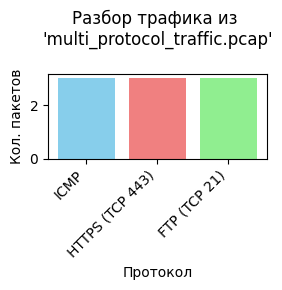


--- Разбор трафика из 'multi_protocol_traffic.pcap' ---
Всего пакетов проанализировано: 9
  > ICMP: 3 пакетов
  > HTTPS (TCP 443): 3 пакетов
  > FTP (TCP 21): 3 пакетов


In [5]:
from scapy.all import rdpcap, IP, TCP, ICMP
import matplotlib.pyplot as plt
import numpy as np

# 1. Чтение сгенерированного PCAP-файла
file_name = "multi_protocol_traffic.pcap"
packets = rdpcap(file_name)

# 2. Инициализация счетчиков
protocol_counts = {
    "ICMP": 0,
    "HTTPS (TCP 443)": 0,
    "FTP (TCP 21)": 0,
    "Другой TCP": 0,
    "Другой IP": 0, # Изменил "Неизвестный" на "Другой IP" для лучшей категории
    "Не-IP": 0     # Для пакетов, которые не являются IP (например, ARP)
}

# 3. Анализ каждого пакета
for pkt in packets:
    if pkt.haslayer(IP):
        if pkt.haslayer(ICMP):
            protocol_counts["ICMP"] += 1
        elif pkt.haslayer(TCP):
            dport = pkt[TCP].dport
            if dport == 443:
                protocol_counts["HTTPS (TCP 443)"] += 1
            elif dport == 21:
                protocol_counts["FTP (TCP 21)"] += 1
            else:
                protocol_counts["Другой TCP"] += 1
        else:
            protocol_counts["Другой IP"] += 1
    else:
        protocol_counts["Не-IP"] += 1

# 4. Фильтрация протоколов с нулевым количеством для лучшей визуализации
filtered_counts = {k: v for k, v in protocol_counts.items() if v > 0}

# 5. Подготовка данных для визуализации
protocols = list(filtered_counts.keys())
counts = list(filtered_counts.values())

# 6. Визуализация с использованием Matplotlib
plt.figure(figsize=(3, 3)) # Устанавливаем размер графика
plt.bar(protocols, counts, color=['skyblue', 'lightcoral', 'lightgreen', 'gold', 'violet'])

plt.xlabel("Протокол")
plt.ylabel("Кол. пакетов")
plt.title(f"Разбор трафика из \n'{file_name}'\n")
plt.xticks(rotation=45, ha="right") # Поворот меток по оси X для лучшей читаемости
plt.tight_layout() # Автоматически настраивает параметры рисунка для плотного размещения элементов
plt.show()

# 7. Дополнительный текстовый вывод (как в предыдущем примере)
print(f"\n--- Разбор трафика из '{file_name}' ---")
print(f"Всего пакетов проанализировано: {len(packets)}")
for proto, count in protocol_counts.items():
    if count > 0:
        print(f"  > {proto}: {count} пакетов")

# 5.5.5 Пример с реальным PCAP-файлом


В этом примере загружается PCAP-файл и выполняется базовый анализ IP-протоколов, адресов источников и портов назначения. Сам по себе необычный номер IP-протокола не доказывает наличие фаззинга: для такого вывода нужны дополнительные признаки и контекст. **Фаззинг** — это тестирование программ или сетевых стеков с помощью неожиданных, некорректных или случайно сформированных входных данных с целью обнаружить ошибки и уязвимости.
Код пытается скачать указанный файл, если его нет в текущей рабочей папке. Если файл недоступен по этой ссылке, укажите имя существующего PCAP-файла или выберите другой учебный дамп.

[Wireshark — коллекция автоматических захватов](https://www.wireshark.org/download/automated/captures/)

Можно использовать и другой PCAP-файл из надёжного учебного источника.

### 1. Пример анализа файла

[fuzz-2025-07-09-17925.pcap]
[!] Файл fuzz-2025-07-09-17925.pcap не найден. Скачивание с Wireshark...
[+] Файл успешно скачан.
[+] Всего пакетов загружено: 1210

--- A. Распределение по Протоколам (Сводка) ---
ПРИМЕЧАНИЕ: Наличие IP_PROTO_XXX указывает на АНОМАЛЬНЫЙ трафик фаззинга.
TCP       : 1067
NON_IP    : 66
UDP       : 41
IP_PROTO_170: 12
DDP       : 3
IP_PROTO_105: 2
HOPOPT    : 2
IP_PROTO_126: 1
IP_PROTO_164: 1
IP_PROTO_79: 1

--- B. Активность Узлов (Идентификация Фаззера и Цели) ---
Самый активный IP-источник (Вероятный Фаззер): 192.168.50.134 (455 пакетов)
Самый активный IP-получатель (Цель Атаки): 212.170.242.55 (159 пакетов)

--- C. Цели Фаззинга (Топ-5 Портов) ---
TCP/80    (HTTP   ): 357 пакетов
TCP/1112  (UNKNOWN): 98 пакетов
TCP/1113  (UNKNOWN): 69 пакетов
TCP/443   (HTTPS  ): 54 пакетов
TCP/1083  (UNKNOWN): 48 пакетов

--- D. Визуализация Распределения Трафика ---


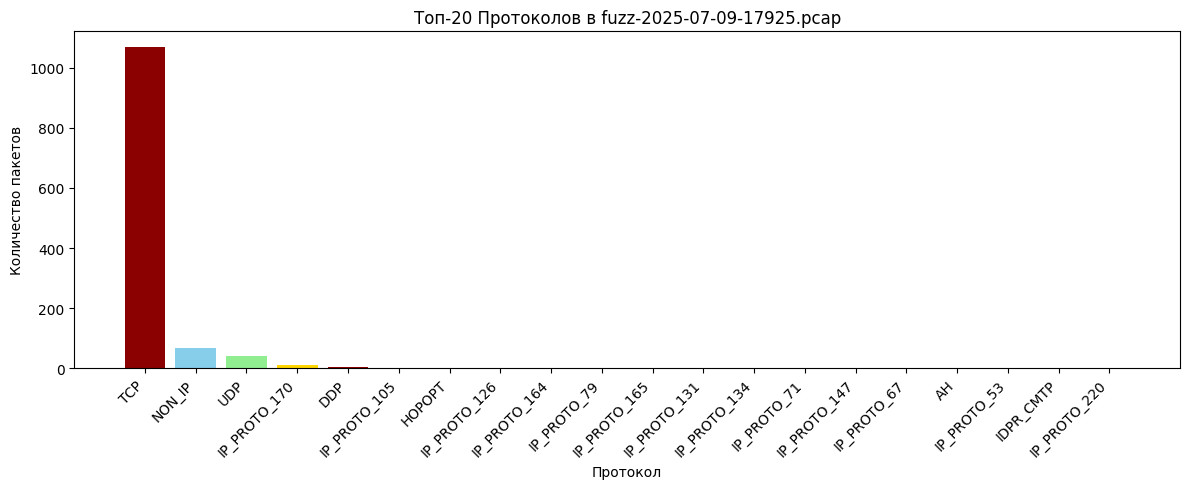

In [18]:
from scapy.all import rdpcap, IP, TCP, UDP, IP_PROTOS
from collections import Counter
import requests
import os
import matplotlib.pyplot as plt

# --- КОНФИГУРАЦИЯ ---
FILE_NAME = "fuzz-2025-07-09-17925.pcap"
DOWNLOAD_URL = f"https://www.wireshark.org/download/automated/captures/{FILE_NAME}"

# --- 1. ЗАГРУЗКА И ЧТЕНИЕ ФАЙЛА ---
print(f"[{FILE_NAME}]")

if not os.path.exists(FILE_NAME):
    print(f"[!] Файл {FILE_NAME} не найден. Скачивание с Wireshark...")
    try:
        r = requests.get(DOWNLOAD_URL, allow_redirects=True, timeout=10)
        r.raise_for_status()
        with open(FILE_NAME, 'wb') as f:
            f.write(r.content)
        print(f"[+] Файл успешно скачан.")
    except requests.exceptions.RequestException as e:
        print(f"[-] Ошибка при скачивании. Анализ невозможен. {e}")
        raise SystemExit(e)

try:
    packets = rdpcap(FILE_NAME)
    print(f"[+] Всего пакетов загружено: {len(packets)}\n")
except Exception as e:
    print(f"[-] Ошибка чтения PCAP-файла: {e}")
    raise SystemExit(e)


# --- 2. БАЗОВЫЙ АНАЛИЗ ПРОТОКОЛОВ (НАДЕЖНОЕ ИСПРАВЛЕНИЕ ОШИБКИ IP_PROTOS) ---
protocol_counts = Counter()
source_ips = Counter()
destination_ports = Counter()

# Главное исправление: Преобразуем IP_PROTOS в обычный Python-словарь для надежного использования метода .get()
IP_PROTO_MAP = dict(IP_PROTOS)

for pkt in packets:
    if pkt.haslayer(IP):
        # 2.1. Подсчет протоколов
        proto_number = pkt[IP].proto
        # Используем .get() стандартного словаря для безопасного преобразования
        protocol_name = IP_PROTO_MAP.get(proto_number, f"IP_PROTO_{proto_number}")

        protocol_counts[protocol_name.upper()] += 1

        # 2.2. Подсчет IP-адресов
        source_ips[pkt[IP].src] += 1

        # 2.3. Подсчет портов (L4)
        if pkt.haslayer(TCP):
            destination_ports[("TCP", pkt[TCP].dport)] += 1
        elif pkt.haslayer(UDP):
            destination_ports[("UDP", pkt[UDP].dport)] += 1
    else:
        protocol_counts["NON_IP"] += 1


# --- 3. ВЫВОД РЕЗУЛЬТАТОВ АНАЛИЗА ---

print("--- A. Распределение по Протоколам (Сводка) ---")
print("ПРИМЕЧАНИЕ: Наличие IP_PROTO_XXX указывает на АНОМАЛЬНЫЙ трафик фаззинга.")
for proto, count in protocol_counts.most_common(10): # Выводим топ-10
    print(f"{proto.ljust(10)}: {count}")


print("\n--- B. Активность Узлов (Идентификация Фаззера и Цели) ---")
if source_ips:
    # 3.1. Идентификация отправителя фаззинга
    scanner_ip, count = source_ips.most_common(1)[0]
    print(f"Самый активный IP-источник (Вероятный Фаззер): {scanner_ip} ({count} пакетов)")

    # 3.2. Идентификация цели
    target_ips = Counter([pkt[IP].dst for pkt in packets if pkt.haslayer(IP) and pkt[IP].src == scanner_ip])
    if target_ips:
        target_ip, t_count = target_ips.most_common(1)[0]
        print(f"Самый активный IP-получатель (Цель Атаки): {target_ip} ({t_count} пакетов)")


print("\n--- C. Цели Фаззинга (Топ-5 Портов) ---")
for (proto, port), count in destination_ports.most_common(5):
    # Пытаемся определить стандартный сервис
    service = "UNKNOWN"
    if port == 80 and proto == "TCP": service = "HTTP"
    elif port == 21 and proto == "TCP": service = "FTP"
    elif port == 53: service = "DNS"
    elif port == 443 and proto == "TCP": service = "HTTPS"

    print(f"{proto}/{str(port).ljust(5)} ({service.ljust(7)}): {count} пакетов")


# --- 4. ВИЗУАЛИЗАЦИЯ ---
print("\n--- D. Визуализация Распределения Трафика ---")
plt.figure(figsize=(12, 5))
# Берем только топ-20 протоколов, чтобы график был читаемым
protocols_to_plot = [p for p, c in protocol_counts.most_common(20) if c > 0]
counts_to_plot = [c for p, c in protocol_counts.most_common(20) if c > 0]

plt.bar(protocols_to_plot, counts_to_plot, color=['darkred', 'skyblue', 'lightgreen', 'gold'])
plt.xlabel("Протокол")
plt.ylabel("Количество пакетов")
plt.title(f"Топ-20 Протоколов в {FILE_NAME}")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 1. Вариант анализа PCAP-файла с помощью Pandas

Загружено пакетов: 1210

🔹 Первые 5 строк данных:


,src_ip,dst_ip,protocol
0,192.168.50.134,192.168.50.1,UDP
1,192.168.50.1,192.168.50.134,UDP
2,192.168.50.134,192.168.50.1,TCP
3,192.168.50.1,192.168.50.134,6
4,192.168.50.134,192.168.50.1,TCP



 Топ-5 IP-источников:


src_ip
192.168.50.134    455
212.170.242.55    242
83.97.120.45      135
192.168.50.1       82
216.109.119.65     32
Name: count, dtype: int64


 Топ-5 IP-получателей:


dst_ip
192.168.50.134    588
212.170.242.55    169
83.97.120.45       91
192.168.50.1       78
216.109.119.65     25
Name: count, dtype: int64


 Протоколы по популярности:


protocol
TCP    1014
6        53
UDP      38
170      12
17        3
37        3
105       2
0         2
126       1
164       1
79        1
165       1
131       1
134       1
71        1
147       1
67        1
51        1
53        1
38        1
220       1
81        1
114       1
196       1
75        1
Name: count, dtype: int64

<Axes: title={'center': 'Распределение протоколов'}, xlabel='protocol'>

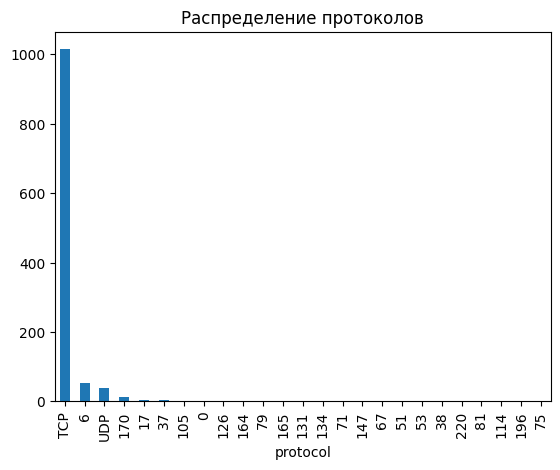

In [19]:
#  Анализ pcap-файла с помощью Scapy

from scapy.all import rdpcap, IP, TCP, UDP
from collections import Counter
import pandas as pd

# === 1. Загружаем pcap-файл ===
# Укажите путь к вашему файлу:
pcap_file = "fuzz-2025-07-09-17925.pcap"   # <-- замените на ваш путь

packets = rdpcap(pcap_file)
print(f"Загружено пакетов: {len(packets)}")

# === 2. Извлекаем базовую информацию ===
src_ips = []
dst_ips = []
protocols = []

for pkt in packets:
    if IP in pkt:
        ip_layer = pkt[IP]
        src_ips.append(ip_layer.src)
        dst_ips.append(ip_layer.dst)
        if TCP in pkt:
            protocols.append("TCP")
        elif UDP in pkt:
            protocols.append("UDP")
        else:
            protocols.append(ip_layer.proto)

# === 3. Создаём DataFrame для анализа ===
df = pd.DataFrame({
    "src_ip": src_ips,
    "dst_ip": dst_ips,
    "protocol": protocols
})

print("\n🔹 Первые 5 строк данных:")
display(df.head())

# === 4. Топ источников и получателей ===
print("\n Топ-5 IP-источников:")
display(df["src_ip"].value_counts().head())

print("\n Топ-5 IP-получателей:")
display(df["dst_ip"].value_counts().head())

print("\n Протоколы по популярности:")
display(df["protocol"].value_counts())

# === 5. Визуализация распределения протоколов ===
df["protocol"].value_counts().plot(kind="bar", title="Распределение протоколов")


# Глоссарий по анализу PCAP и сетевому мониторингу

| Термин / Аббревиатура | Расшифровка / Определение |
|------------------------|----------------------------|
| **PCAP (Packet Capture)** | Формат и процесс захвата сетевых пакетов для последующего анализа. Хранит заголовки и полезную нагрузку каждого пакета. |
| **PCAPNG (PCAP Next Generation)** | Современный формат дампов пакетов, поддерживающий метаданные, комментарии и несколько интерфейсов. |
| **Пакет (Packet)** | Минимальная единица передачи данных в сети, содержащая заголовки (IP, TCP/UDP и т.д.) и полезную нагрузку. |
| **Захват трафика (Packet Capture)** | Процесс перехвата сетевых пакетов с интерфейса в реальном времени для анализа. |
| **Сниффер (Sniffer)** | Программа, предназначенная для перехвата и анализа сетевых пакетов (например, Wireshark, tcpdump). |
| **Wireshark** | Графический инструмент для анализа сетевого трафика и расшифровки сотен протоколов. |
| **tcpdump** | Консольная утилита для захвата и фильтрации сетевых пакетов в формате PCAP. |
| **TShark** | Консольная версия Wireshark, используемая для автоматизированного анализа PCAP-файлов. |
| **Scapy** | Python-библиотека для создания, анализа и модификации сетевых пакетов. Подходит для тестирования и пентестов. |
| **PyShark** | Python-обёртка над TShark, обеспечивающая доступ к данным пакетов через высокоуровневый API. |
| **DPKT** | Высокопроизводительная библиотека Python для низкоуровневого парсинга PCAP-файлов. |
| **PyPCAPKit** | Модульная библиотека Python для глубокого протокольного анализа и реконструкции сетевых потоков. |
| **Zeek (Bro)** | Система сетевого мониторинга и анализа поведения, создающая логи и события из сетевого трафика. |
| **Suricata** | Система обнаружения вторжений (IDS/IPS) с возможностью захвата и анализа трафика. |
| **Snort** | Популярная IDS/IPS-система для выявления сетевых атак на основе сигнатур. |
| **IDS / IPS** | Intrusion Detection / Prevention System — системы обнаружения и предотвращения вторжений. |
| **NetFlow / IPFIX / sFlow** | Форматы и технологии для сбора статистики сетевых потоков (без сохранения полезной нагрузки). |
| **Stream Reconstruction (Реконструкция потоков)** | Процесс объединения отдельных пакетов в полные TCP/UDP-сессии для анализа взаимодействий. |
| **Root Cause Analysis (RCA)** | Анализ первопричины сетевого инцидента на основе захваченных пакетов. |
| **Latency (Задержка)** | Время прохождения пакета от источника до назначения. |
| **Throughput (Пропускная способность)** | Объём данных, переданных за единицу времени. |
| **BPF (Berkeley Packet Filter)** | Механизм фильтрации пакетов на уровне ядра при захвате (например, `tcpdump port 80`). |
| **Forensics (Форензика)** | Расследование инцидентов с использованием цифровых артефактов, включая PCAP. |
| **SIEM (Security Information and Event Management)** | Система управления событиями информационной безопасности, объединяющая логи, алерты и сетевые данные. |
| **TLS / SSL** | Протоколы шифрования трафика, затрудняющие анализ содержимого PCAP. |
| **Metadata (Метаданные)** | Данные о данных — информация о времени, IP-адресах, портах и т. д., не содержащая полезную нагрузку. |
| **SPAN / TAP** | Методы зеркалирования сетевого трафика для анализа без вмешательства в передачу данных. |
| **Retention Policy (Политика хранения)** | Правила по сроку и условиям хранения PCAP-файлов, часто регулируемые нормами безопасности. |
| **Anonymization (Анонимизация)** | Процесс удаления или маскирования чувствительных данных в PCAP-файлах. |
| **Flow (Поток)** | Совокупность пакетов между двумя конечными точками, определяемая 5-tuple: IP src/dst, порт src/dst, протокол. |

---

###  Итог
Разбор PCAP — это фундаментальный инструмент сетевой диагностики, форензики и мониторинга.  
Знание ключевых понятий и технологий позволяет эффективно:
- выявлять инциденты,  
- анализировать производительность,  
- документировать события,  
- и строить защищённые системы наблюдаемости.


## Пример к главе 6

In [1]:
import pandas as pd
from scapy.all import rdpcap, IP, TCP, UDP
from collections import defaultdict

# --- Конфигурация и вводные данные ---
PCAP_FILE_PATH = "fuzz-2025-07-09-17925(1).pcap"
FLOW_TIMEOUT_SECONDS = 30 # Имитируем тайм-аут неактивности Flow

# Словарь для хранения агрегированных Flow-данных
# Ключ: (src_ip, dst_ip, src_port, dst_port, protocol)
flows = defaultdict(lambda: {
    'start_time': None,
    'end_time': None,
    'bidirectional_packets': 0,
    'bidirectional_bytes': 0,
    'dst_port': None # Сохраняем порт для анализа сканирования
})

print(f"Загрузка и анализ пакетов из файла: {PCAP_FILE_PATH}...")

# Загрузка всех пакетов из PCAP-файла
try:
    packets = rdpcap(PCAP_FILE_PATH)
except FileNotFoundError:
    print(f"ОШИБКА: Файл {PCAP_FILE_PATH} не найден. Проверьте путь.")
    exit()
except Exception as e:
    print(f"ОШИБКА при чтении PCAP-файла: {e}")
    exit()

# --- Имитация Flow Caching ---
# Итерируем по пакетам и агрегируем их в потоки
for packet in packets:
    if not packet.haslayer(IP):
        continue

    # Определяем ключевые поля (7-tuple, но упрощенный до 5-tuple для Scapy)
    src_ip = packet[IP].src
    dst_ip = packet[IP].dst
    
    current_time = float(packet.time)
    
    if packet.haslayer(TCP):
        proto_name = 'TCP'
        src_port = packet[TCP].sport
        dst_port = packet[TCP].dport
    elif packet.haslayer(UDP):
        proto_name = 'UDP'
        src_port = packet[UDP].sport
        dst_port = packet[UDP].dport
    else:
        # Для других протоколов (например, ICMP) используем порт 0
        proto_name = packet[IP].proto
        src_port = 0
        dst_port = 0

    # Создаем два возможных ключа потока (для двунаправленного Flow)
    # Поток A -> B
    key_ab = (src_ip, dst_ip, src_port, dst_port, proto_name)
    # Поток B -> A (реверсивный)
    key_ba = (dst_ip, src_ip, dst_port, src_port, proto_name)

    flow_key = None
    
    # 1. Ищем, соответствует ли пакет существующему потоку (в любом направлении)
    if key_ab in flows:
        flow_key = key_ab
    elif key_ba in flows:
        flow_key = key_ba
    
    # 2. Если Flow найден, обновляем его
    if flow_key:
        flow = flows[flow_key]
        flow['bidirectional_packets'] += 1
        flow['bidirectional_bytes'] += len(packet)
        flow['end_time'] = current_time
    # 3. Если Flow не найден, создаем новый (используем key_ab)
    else:
        flow_key = key_ab
        flow = flows[flow_key]
        flow['start_time'] = current_time
        flow['end_time'] = current_time
        flow['bidirectional_packets'] = 1
        flow['bidirectional_bytes'] = len(packet)
        flow['dst_port'] = dst_port # Добавляем порт
        flows[flow_key] = flow

# --- Преобразование в DataFrame ---
data = []
for key, flow in flows.items():
    src_ip, dst_ip, src_port, dst_port, proto_name = key
    duration_s = flow['end_time'] - flow['start_time']
    
    data.append({
        'src_ip': src_ip,
        'dst_ip': dst_ip,
        'src_port': src_port,
        'dst_port': flow['dst_port'], # Используем сохраненный dst_port
        'protocol': proto_name,
        'bidirectional_packets': flow['bidirectional_packets'],
        'bidirectional_bytes': flow['bidirectional_bytes'],
        'duration_ms': duration_s * 1000 # Переводим в миллисекунды
    })

df = pd.DataFrame(data)
print(f"Имитация Flow завершена. Всего обработано потоков: {len(df)}\n")

# --- 1. Обнаружение Угрозы: DDoS/SYN Flood Атака ---
# (Код анализа остается точно таким же, как в предыдущем примере)
def analyze_ddos_risk(df, threshold_packets=5000):
    """
    Анализирует агрегированное количество пакетов по IP-адресу назначения.
    """
    print("--- 1. Обнаружение Угрозы: Анализ DDoS ---")

    ddos_candidates = df.groupby('dst_ip').agg(
        total_packets=('bidirectional_packets', 'sum'),
        total_flows=('dst_ip', 'size'),
        average_duration_ms=('duration_ms', 'mean')
    ).reset_index()

    # Для небольшого PCAP-файла используем низкий порог (например, 100 пакетов)
    current_threshold = 100 
    attack_flows = ddos_candidates[ddos_candidates['total_packets'] > current_threshold]

    if not attack_flows.empty:
        print(f"!!! АНОМАЛИЯ (DDoS Risk) ОБНАРУЖЕНА! Порог: > {current_threshold} пакетов.")
        for index, row in attack_flows.iterrows():
            print(f"  > IP Назначения: {row['dst_ip']}")
            print(f"    Общее кол-во пакетов: {row['total_packets']}")
            print(f"    Общее кол-во потоков: {row['total_flows']}")
            print(f"    Средняя длительность потока: {row['average_duration_ms']:.2f} мс.")
    else:
        print(f"Подозрительных DDoS-атак не обнаружено (ни один адрес не превысил {current_threshold} пакетов).")
    print("-" * 50)


# --- 2. Обнаружение Аномалии: Сетевое Сканирование ---
# (Код анализа остается точно таким же, как в предыдущем примере)
def analyze_port_scanning(df, threshold_unique_ports=10):
    """
    Анализирует хосты на предмет инициирования большого числа уникальных портов назначения.
    """
    print("--- 2. Обнаружение Аномалии: Анализ Сетевого Сканирования ---")
    
    current_threshold = 5 # Для небольшого PCAP-файла используем низкий порог

    # Группируем по IP-адресу источника и считаем количество уникальных портов назначения.
    scanner_candidates = df.groupby('src_ip').agg(
        total_unique_ports=('dst_port', pd.Series.nunique),
        total_flows=('src_ip', 'size'),
        average_packets_per_flow=('bidirectional_packets', 'mean')
    ).reset_index()

    scan_flows = scanner_candidates[scanner_candidates['total_unique_ports'] > current_threshold]

    if not scan_flows.empty:
        print(f"!!! АНОМАЛИЯ (Сетевое Сканирование) ОБНАРУЖЕНА! Порог: > {current_threshold} уникальных портов.")
        for index, row in scan_flows.iterrows():
            print(f"  > IP Источника (Сканер): {row['src_ip']}")
            print(f"    Уникальных портов назначения: {row['total_unique_ports']} (подозрительно много).")
            print(f"    Общее кол-во потоков: {row['total_flows']}")
            print(f"    Среднее кол-во пакетов на поток: {row['average_packets_per_flow']:.2f}")
    else:
        print(f"Подозрительных сканирований портов не обнаружено (ни один хост не превысил {current_threshold} уникальных портов).")
    print("-" * 50)

# --- Запуск анализа ---
analyze_ddos_risk(df)
analyze_port_scanning(df)

Загрузка и анализ пакетов из файла: fuzz-2025-07-09-17925(1).pcap...
Имитация Flow завершена. Всего обработано потоков: 313

--- 1. Обнаружение Угрозы: Анализ DDoS ---
!!! АНОМАЛИЯ (DDoS Risk) ОБНАРУЖЕНА! Порог: > 100 пакетов.
  > IP Назначения: 192.168.50.1
    Общее кол-во пакетов: 128
    Общее кол-во потоков: 24
    Средняя длительность потока: 4917.72 мс.
  > IP Назначения: 192.168.50.134
    Общее кол-во пакетов: 271
    Общее кол-во потоков: 107
    Средняя длительность потока: 2900.31 мс.
  > IP Назначения: 212.170.242.55
    Общее кол-во пакетов: 269
    Общее кол-во потоков: 33
    Средняя длительность потока: 374.57 мс.
  > IP Назначения: 83.97.120.45
    Общее кол-во пакетов: 195
    Общее кол-во потоков: 21
    Средняя длительность потока: 5453.50 мс.
--------------------------------------------------
--- 2. Обнаружение Аномалии: Анализ Сетевого Сканирования ---
!!! АНОМАЛИЯ (Сетевое Сканирование) ОБНАРУЖЕНА! Порог: > 5 уникальных портов.
  > IP Источника (Сканер): 192.168

# Домашние задания к главе 5. Инструменты анализа пакетов

## Домашнее задание 1. Статистический анализ PCAP-файла

**Цель:** научиться загружать сетевой дамп с помощью Scapy, извлекать сведения о пакетах и представлять результаты анализа.

**Задание**

1. Найдите учебный PCAP/PCAPNG-файл в коллекции [Wireshark Sample Captures](https://wiki.wireshark.org/SampleCaptures) либо используйте файл, предоставленный преподавателем.
2. Загрузите файл в Jupyter Notebook с помощью `rdpcap()` из Scapy.
3. Определите:
   - общее количество пакетов;
   - количество и долю пакетов IPv4/IPv6 (если они присутствуют), TCP, UDP и ICMP;
   - пять наиболее часто встречающихся IP-адресов источника и назначения;
   - минимальный, максимальный и средний размер пакета.
4. Представьте статистику по протоколам в таблице Pandas и постройте столбчатую диаграмму распределения пакетов по протоколам.
5. Напишите краткий вывод (5–8 предложений): какие протоколы преобладают, какие узлы наиболее активны и какие ограничения есть у проведённого анализа.

**Требования к сдаче:** ноутбук с кодом, таблицей, диаграммой и выводами. Код должен корректно обрабатывать пакеты, в которых отсутствуют IP- или TCP/UDP-заголовки.

**Критерии оценки (10 баллов):** корректность загрузки и подсчётов — 4; таблица и визуализация — 2; обработка пакетов разных типов — 2; интерпретация результатов — 2.

---

## Домашнее задание 2. Обнаружение подозрительной TCP-активности в PCAP

**Цель:** применить эвристический анализ сетевого трафика для выявления признаков возможного SYN-сканирования.

**Задание**

1. Используйте учебный PCAP-файл, предоставленный преподавателем, или самостоятельно создайте небольшой **синтетический** дамп с тестовыми пакетами Scapy. Не выполняйте сканирование чужих сетей и не отправляйте пакеты на реальные внешние узлы.
2. Прочитайте дамп и сгруппируйте TCP-пакеты по IP-адресу источника.
3. Для каждого источника подсчитайте:
   - число TCP-пакетов с установленным флагом SYN;
   - число уникальных портов назначения, на которые направлены SYN-пакеты;
   - число пакетов с флагом SYN без установленного ACK.
4. Реализуйте эвристическое правило для пометки подозрительной активности. Например, считать источник кандидатом на проверку, если в дампе от него зафиксировано не менее 5 SYN-пакетов к 5 или более различным портам назначения. Порог должен быть параметром, который можно изменить.
5. Выведите таблицу результатов и постройте график количества SYN-пакетов по источникам. Сравните результаты для двух разных порогов.
6. Объясните, почему это правило не доказывает факт атаки: укажите как минимум три возможные причины ложного срабатывания и два ограничения анализа одного PCAP-файла.

**Требования к сдаче:** ноутбук с кодом, таблицей, графиком и кратким аналитическим заключением (8–12 предложений). При отсутствии TCP-пакетов программа должна завершаться без ошибки и сообщать, что подходящих пакетов не найдено.

**Критерии оценки (10 баллов):** корректный разбор TCP-флагов и портов — 3; группировка и параметризуемое правило — 3; график и сравнение порогов — 2; обсуждение ложных срабатываний и ограничений — 2.
